# Week 6 · Topic 4 — Apply, Lambda and Finishing Up

**Box we are building: STORE + PROCESS, the whole job**

A `lambda` is a `def` you don't bother naming, for a one-line function you are
only going to use once — usually right inside `.apply()`.

> **Already know this?** Skip to the *Topic 4 Challenge*.

---
## 1. `.apply()` runs a function on every value in a column

Start with a normal function, the way Week 3 taught it.

In [ ]:
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["used"] / servers["total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

### Your turn
Write your own single-argument function and `.apply()` it to the `used` column.

In [1]:
import pandas as pd

servers = pd.read_csv("../01 - Series and DataFrame/servers.csv")

def check_usage(used):
    if used >= 100:
        return "OVER LIMIT"
    elif used >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["used"].apply(check_usage)

print(servers)

  hostname  used  total region      status
0    R-001    87    100   west          OK
1    R-002   120    100  north  OVER LIMIT
2    R-003    45    100   west          OK
3    R-004    65    100   east          OK
4    R-005    92    100   west     WARNING


---
## 2. `lambda` - the same idea, written inline

`lambda parameters: expression` — that IS the whole function. Only one
expression allowed — no `if`/`elif`/`else` statements, no loops.

In [ ]:
double = lambda x: x * 2
print(double(21))     # 42 - same as def double(x): return x * 2

```
def classify(p):                    lambda p: (
    if p >= 100:                        "OVER LIMIT" if p >= 100
        return "OVER LIMIT"             else "WARNING" if p >= 90
    elif p >= 90:                       else "OK"
        return "WARNING"             )
    else:
        return "OK"

same logic, same result - a block of statements vs one expression
```

### Your turn
Write `classify` as a lambda with a chained conditional, and check it gives the same result as the `def` version for every row.

In [2]:
import pandas as pd

servers = pd.read_csv("../01 - Series and DataFrame/servers.csv")

servers["percent"] = (servers["used"] / servers["total"]) * 100


def classify_def(p):
    if p >= 100:
        return "OVER LIMIT"
    elif p >= 90:
        return "WARNING"
    else:
        return "OK"


servers["status_def"] = servers["percent"].apply(classify_def)


classify_lambda = lambda p: "OVER LIMIT" if p >= 100 else ("WARNING" if p >= 90 else "OK")


servers["status_lambda"] = servers["percent"].apply(classify_lambda)


print(servers[["hostname", "percent", "status_def", "status_lambda"]])

print(servers["status_def"] == servers["status_lambda"])

  hostname  percent  status_def status_lambda
0    R-001     87.0          OK            OK
1    R-002    120.0  OVER LIMIT    OVER LIMIT
2    R-003     45.0          OK            OK
3    R-004     65.0          OK            OK
4    R-005     92.0     WARNING       WARNING
0    True
1    True
2    True
3    True
4    True
dtype: bool


---
## 3. `.apply()` with a lambda, and `sort_values(key=...)`

lambda earns its place exactly here — a function small enough to write inline,
used exactly once, right where it is needed.

In [ ]:
servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(servers.sort_values("hostname", key=lambda col: col.str.lower()))

### Your turn
Use `.apply()` with a lambda to add a column `region_upper` — the `region` column, in capitals.

In [3]:
servers["region_upper"] = servers["region"].apply(lambda region: region.upper())

print(servers[["region", "region_upper"]])

  region region_upper
0   west         WEST
1  north        NORTH
2   west         WEST
3   east         EAST
4   west         WEST


---
## 4. Summarising, saving, and a first chart

`describe()` for a quick overview, `.to_csv()` to save, and one chart — straight
off a DataFrame. In a notebook, calling `.plot()` shows the chart inline.

In [ ]:
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

### Your turn
Make a bar chart of servers per region instead of per status.

Matplotlib is building the font cache; this may take a moment.


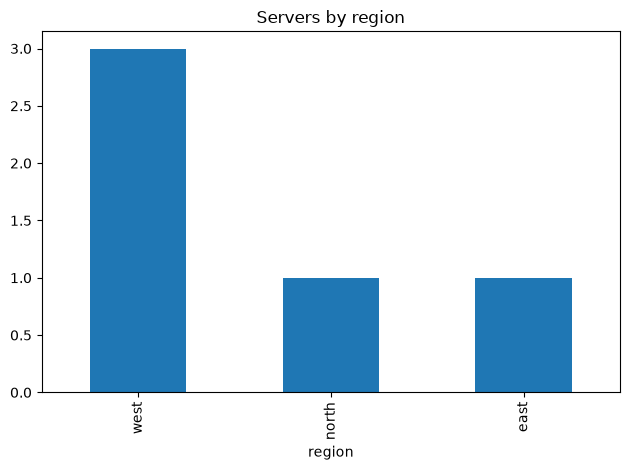

In [6]:
import matplotlib.pyplot as plt

servers["region"].value_counts().plot(kind="bar", title="Servers by region")

plt.tight_layout()
plt.show()

In [5]:
%pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 15.6 MB/s  0:00:00m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 17.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 25.0 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


---
## Topic 4 Challenge

Load `servers.csv`, add `percent` and `status` (via `.apply()` with a lambda),
save the result to a new CSV, and produce one bar chart of the status counts.

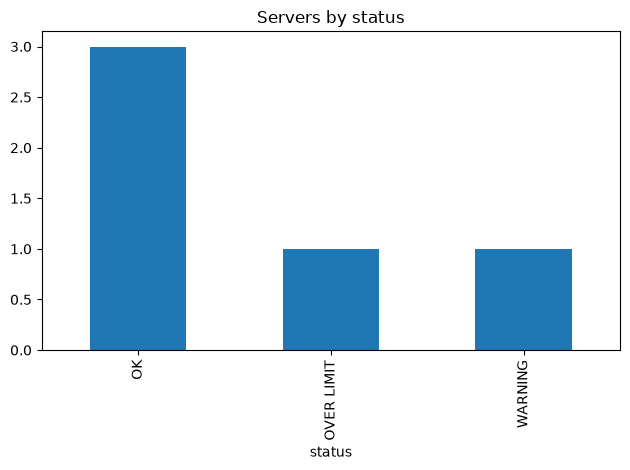

In [7]:
import pandas as pd
import matplotlib.pyplot as plt


servers = pd.read_csv("../01 - Series and DataFrame/servers.csv")


servers["percent"] = (servers["used"] / servers["total"]) * 100


servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)


servers.to_csv("servers_report.csv", index=False)


servers["status"].value_counts().plot(
    kind="bar",
    title="Servers by status"
)

plt.tight_layout()
plt.show()

---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | `df["clean_text"] = df["text"].apply(lambda t: t.strip().lower())` |
| **Cyber Security** | `df["flag"] = df["failed"].apply(lambda n: n >= 3)` |
| **IT** | `df.sort_values("hostname", key=lambda c: c.str.lower())` |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| a lambda with an `if` statement (not an expression) | `SyntaxError` | lambda only allows one expression — use chained `if/else`, or write a `def` |
| reusing the same lambda logic in three places | works, but repeats the logic three times | that is the sign you wanted a named function, not a lambda |
| forgetting `.apply()` and just writing `column.classify()` | `AttributeError` | `.apply(function)` runs your function on every value — the function itself is not a method on the column |
| calling `.plot()` in a plain script and seeing nothing | no chart appears | add `plt.show()` (script) — a notebook shows it automatically |

## Go deeper

`examples/01_apply_and_lambda.py` — apply, lambda syntax, chained conditionals, sort key
`examples/02_summarizing_saving_and_charting.py` — describe, to_csv, a first chart

---
## Recap

| You can now | Using |
|---|---|
| apply a function to a whole column | `column.apply(function)` |
| write a small inline function | `lambda x: expression` |
| choose lambda vs a named function | one-line, used once → lambda; reused or complex → `def` |
| get a quick overview | `.describe()` |
| save a result | `.to_csv(path, index=False)` |
| chart straight from a DataFrame | `.plot(kind=...)` |

**You now have all of CW1's toolkit.** Your mini-project this week closes it out.